# Домашнее задание 2 по теории вероятностей
Выполнила: Джафарова Фарида

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

np.random.seed(42)
plt.rcParams['figure.figsize'] = (8, 4)

## 2.1 Нормальная выборка
μ = 40, σ = 8, 5000 значений

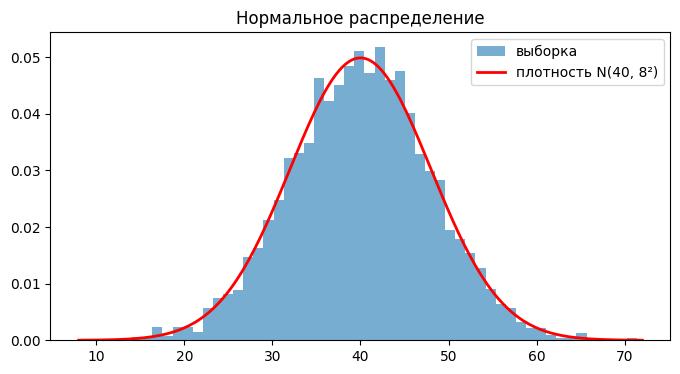

среднее: выборка 40.04, задали 40
ст. откл.: выборка 7.97, задали 8


In [2]:
mu, sigma = 40, 8
sample = np.random.normal(mu, sigma, size=5000)

x = np.linspace(mu - 4*sigma, mu + 4*sigma, 200)
plt.hist(sample, bins=50, density=True, alpha=0.6, label='выборка')
plt.plot(x, stats.norm.pdf(x, mu, sigma), 'r', lw=2, label='плотность N(40, 8²)')
plt.title('Нормальное распределение')
plt.legend()
plt.show()

print(f'среднее: выборка {sample.mean():.2f}, задали {mu}')
print(f'ст. откл.: выборка {sample.std(ddof=1):.2f}, задали {sigma}')

Гистограмма почти идеально повторяет красную кривую плотности: колокол симметричный, вершина около 40, почти все значения лежат в пределах 40 ± 3·8, т.е. от 16 до 64, а дальше попадаются единичные точки.

Среднее выборки 40,04 при заданных 40, стандартное отклонение 7,97 при заданных 8. Отличие небольшое и вполне ожидаемое: выборка конечная, и среднее по 5000 значений обычно отклоняется от μ примерно на σ/√n = 8/√5000 ≈ 0,11. У нас отклонение 0,04, т.е. даже меньше этой величины. Значит, генерация работает как надо, а расхождения объясняются только случайностью.

## 2.2 Биномиальная выборка
n = 1000, p = 0,04, 5000 значений

теория: E = np = 40, σ = √(np(1−p)) = √38,4 ≈ 6,20

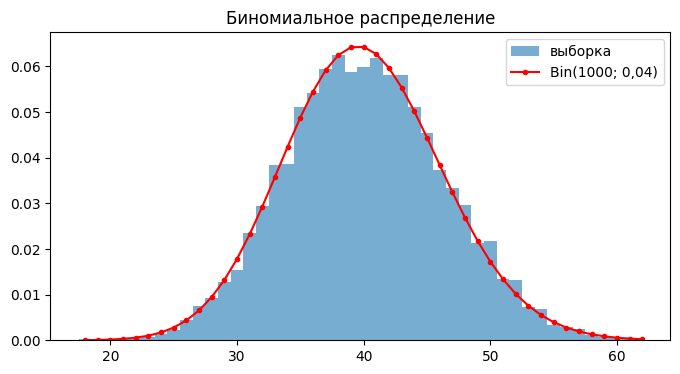

среднее: выборка 40.14, теория 40.00
ст. откл.: выборка 6.25, теория 6.20


In [3]:
n, p = 1000, 0.04
sample = np.random.binomial(n, p, size=5000)

k = np.arange(sample.min(), sample.max() + 1)
plt.hist(sample, bins=k - 0.5, density=True, alpha=0.6, label='выборка')
plt.plot(k, stats.binom.pmf(k, n, p), 'ro-', ms=3, label='Bin(1000; 0,04)')
plt.title('Биномиальное распределение')
plt.legend()
plt.show()

print(f'среднее: выборка {sample.mean():.2f}, теория {n*p:.2f}')
print(f'ст. откл.: выборка {sample.std(ddof=1):.2f}, теория {np.sqrt(n*p*(1-p)):.2f}')

Точки теоретической функции вероятности ложатся на вершины столбиков, так что форма выборки совпадает с Bin(1000; 0,04). Значения целые (это число успехов), поэтому каждый столбик здесь отдельное значение.

Среднее выборки 40,14 против теоретических 40, стандартное отклонение 6,25 против 6,20. Расхождение по среднему 0,14, а обычная ошибка среднего тут 6,2/√5000 ≈ 0,09, т.е. отклонение около 1,5 ошибки, это нормально для случайной выборки.

Ещё видно, что при большом n биномиальное по форме почти не отличается от нормального с тем же E = 40 и σ ≈ 6,2: колокол почти симметричный, правый хвост лишь немного длиннее левого, тк p маленькое. Поэтому число откликов при больших n можно приближать нормальным.

## 2.3 ЦПТ на экспоненциальном
Экспоненциальное – непрерывное, сильно перекошенное вправо (маленькие значения часто, большие редко, но бывают). В numpy scale это среднее, у экспоненциального σ равна среднему, т.е. тут μ = σ = 10.

Беру выборки по 500, считаю среднее, повторяю 10 000 раз. По ЦПТ средние должны лечь на N(μ, σ²/n), т.е. колокол с центром 10 и шириной 10/√500 ≈ 0,45

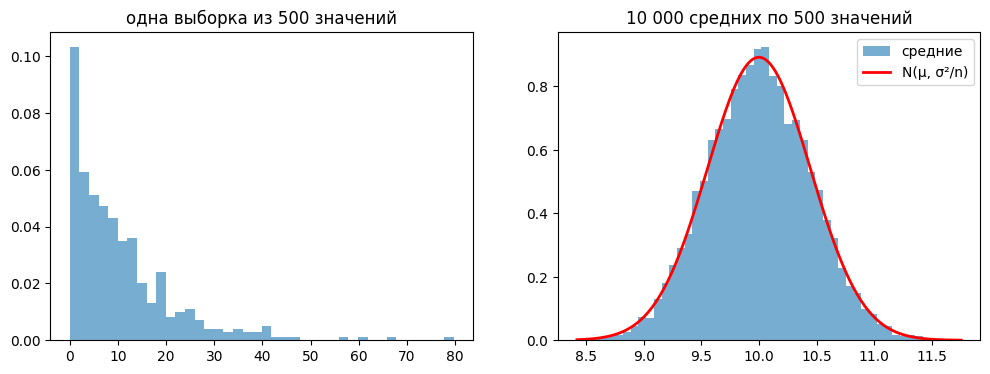

среднее средних 10.000 (μ = 10)
ст. откл. средних 0.446, σ/√n = 0.447


In [4]:
scale = 10
n_per_sample = 500
n_repeats = 10_000

one_sample = np.random.exponential(scale, size=n_per_sample)
means = np.array([np.random.exponential(scale, size=n_per_sample).mean()
                  for _ in range(n_repeats)])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(one_sample, bins=40, density=True, alpha=0.6)
ax[0].set_title('одна выборка из 500 значений')

se = scale / np.sqrt(n_per_sample)   # σ/√n
x = np.linspace(means.min(), means.max(), 200)
ax[1].hist(means, bins=50, density=True, alpha=0.6, label='средние')
ax[1].plot(x, stats.norm.pdf(x, scale, se), 'r', lw=2, label='N(μ, σ²/n)')
ax[1].set_title('10 000 средних по 500 значений')
ax[1].legend()
plt.show()

print(f'среднее средних {means.mean():.3f} (μ = {scale})')
print(f'ст. откл. средних {means.std(ddof=1):.3f}, σ/√n = {se:.3f}')

Слева одна выборка из экспоненциального: большинство значений около нуля, дальше столбики быстро убывают, но отдельные значения доходят до 60–80, т.е. распределение сильно перекошено вправо и на нормальное совсем не похоже.

Справа гистограмма 10 000 средних, и она уже выглядит как обычный симметричный колокол, который хорошо совпадает с кривой N(10, 10²/500). Среднее средних 10,000, т.е. совпадает с μ, а разброс средних 0,446 почти точно равен σ/√n = 0,447.

Это объясняется ЦПТ - сами значения распределены как угодно, но среднее по большому числу независимых значений распределено примерно нормально, с центром в μ и разбросом σ/√n. При этом разброс средних в √500 ≈ 22 раза меньше разброса исходных значений, поэтому среднее по 500 наблюдениям почти всегда лежит в пределах 10 ± 0,9.

## 3.1 Кнопка: стандартная ошибка по формуле
Каждый соискатель откликается или нет, это Бернулли с σ = √(p(1−p)). Конверсия – среднее по n таким величинам, поэтому её стандартная ошибка σ/√n = √(p(1−p)/n).

Сравниваю разницу конверсий, поэтому считаю ещё SE разницы: группы независимые, дисперсии складываются, SE разницы = √(SE₁² + SE₂²)

In [5]:
n_old, x_old = 5000, 155
n_new, x_new = 5000, 170

p_old = x_old / n_old
p_new = x_new / n_new
se_old = np.sqrt(p_old * (1 - p_old) / n_old)
se_new = np.sqrt(p_new * (1 - p_new) / n_new)
se_diff = np.sqrt(se_old**2 + se_new**2)
diff = p_new - p_old

print(f'старая: конверсия {p_old:.1%}, SE = {se_old*100:.3f} п.п.')
print(f'новая:  конверсия {p_new:.1%}, SE = {se_new*100:.3f} п.п.')
print(f'разница {diff*100:.2f} п.п., SE разницы {se_diff*100:.3f} п.п.')
print(f'разница / SE разницы = {diff/se_diff:.2f}')

старая: конверсия 3.1%, SE = 0.245 п.п.
новая:  конверсия 3.4%, SE = 0.256 п.п.
разница 0.30 п.п., SE разницы 0.355 п.п.
разница / SE разницы = 0.85


Конверсия выросла с 3,1% до 3,4%, это +0,3 п.п. или почти +10% относительно старой кнопки, на первый взгляд звучит заметно. Но стандартная ошибка каждой конверсии около 0,25 п.п., т.е. каждая конверсия сама по себе «гуляет» примерно на столько же, сколько составляет весь рост.

Ошибка разницы ещё больше, 0,355 п.п., и разница 0,3 п.п. меньше одной такой ошибки (0,85). Если взять примерно две ошибки в каждую сторону (по правилу 95% для нормального), получится, что настоящая разница может быть где-то от −0,4 до +1,0 п.п. В этот промежуток входит и ноль, и даже небольшое ухудшение.

Предварительный вывод: по этим данным нельзя сказать, что новая кнопка лучше, рост вполне может быть просто случайным.

## 3.2 Проверка симуляцией
Допустим кнопка ни на что не влияет, тогда конверсия в обеих группах одна. Её не знаю, поэтому беру общую по обеим группам: (155 + 170) / 10 000 = 3,25%.

Число откликов в группе из 5000 тогда Bin(5000; 0,0325). Генерирую так обе группы много раз и смотрю, как часто случайно выходит разница не меньше наблюдаемой 0,3 п.п. (= 15 откликов)

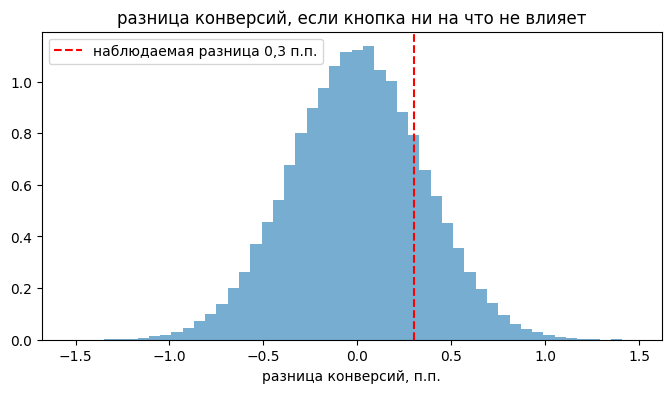

p0 = 3.25%
ст. откл. разниц 0.354 п.п.
доля разниц >= 0,3 п.п.: 20.5%
доля |разница| >= 0,3 п.п.: 41.2%


In [6]:
p0 = (x_old + x_new) / (n_old + n_new)
n_sim = 100_000

clicks_a = np.random.binomial(n_old, p0, size=n_sim)
clicks_b = np.random.binomial(n_new, p0, size=n_sim)
diffs = (clicks_b - clicks_a) / n_old * 100   # в п.п.

# 0,3 п.п. это 15 откликов, сравниваю в откликах, чтобы не было проблем с округлением float
share = np.mean(clicks_b - clicks_a >= 15)
share_abs = np.mean(np.abs(clicks_b - clicks_a) >= 15)

step = 100 / n_old   # разница меняется шагами по 0,02 п.п.
bins = np.arange(diffs.min() - step/2, diffs.max() + step, 3*step)
plt.hist(diffs, bins=bins, density=True, alpha=0.6)
plt.axvline(0.3, color='r', ls='--', label='наблюдаемая разница 0,3 п.п.')
plt.xlabel('разница конверсий, п.п.')
plt.title('разница конверсий, если кнопка ни на что не влияет')
plt.legend()
plt.show()

print(f'p0 = {p0:.2%}')
print(f'ст. откл. разниц {diffs.std(ddof=1):.3f} п.п.')
print(f'доля разниц >= 0,3 п.п.: {share:.1%}')
print(f'доля |разница| >= 0,3 п.п.: {share_abs:.1%}')

Гистограмма показывает, какие разницы конверсий получаются чисто случайно, если обе группы на самом деле одинаковые. Центр у неё в нуле, а разброс 0,354 п.п., что почти точно совпадает с ошибкой разницы 0,355 п.п. из 3.1, т.е. формула и симуляция сходятся.

Наблюдаемые 0,3 п.п. находятся совсем недалеко от центра. Разница 0,3 п.п. и больше в пользу новой кнопки получилась в 20,5% симуляций, т.е. примерно в каждом пятом эксперименте, хотя кнопка там ни на что не влияет. Если смотреть отклонение в любую сторону, то таких случаев 41%. Получается, что такой результат для эксперимента без эффекта вполне обычный.

Вывод: 0,3 п.п. – это шум, эффект новой кнопки по этим данным не подтверждается. Чтобы рост 0,3 п.п. стал заметен, нужно, чтобы он был хотя бы в 2 раза больше ошибки разницы, т.е. ошибка должна быть около 0,15 п.п. вместо 0,355. Ошибка уменьшается как 1/√n, значит данных нужно примерно в (0,355/0,15)² ≈ 5,6 раза больше, около 28 000 соискателей в каждой группе вместо 5000.

## 3.3 Выбросы во времени сессий
Три сигмы: выброс, если значение дальше 3σ от среднего (σ считаю по выборке, ddof=1).

Перцентили: выброс, если больше 75-й + 1,5 × (75-й − 25-й) или меньше 25-й − 1,5 × (75-й − 25-й)

In [7]:
t = np.array([3, 4, 4, 5, 5, 6, 6, 7, 8, 52])

# три сигмы
m, s = t.mean(), t.std(ddof=1)
low_3s, up_3s = m - 3*s, m + 3*s
print(f'среднее {m:.1f}, σ = {s:.2f}')
print(f'границы трёх сигм: [{low_3s:.1f}; {up_3s:.1f}]')
print('выбросы по 3σ:', t[(t < low_3s) | (t > up_3s)])

# перцентили (Тьюки)
p25, p75 = np.percentile(t, [25, 75])
width = p75 - p25   # 75-й − 25-й
low_pct, up_pct = p25 - 1.5*width, p75 + 1.5*width
print(f'\n25-й перцентиль {p25}, 75-й {p75}')
print(f'границы по перцентилям: [{low_pct}; {up_pct}]')
print('выбросы по перцентилям:', t[(t < low_pct) | (t > up_pct)])

print(f'\nмедиана {np.median(t)}, среднее {m:.1f}')

среднее 10.0, σ = 14.83
границы трёх сигм: [-34.5; 54.5]
выбросы по 3σ: []

25-й перцентиль 4.25, 75-й 6.75
границы по перцентилям: [0.5; 10.5]
выбросы по перцентилям: [52]

медиана 5.5, среднее 10.0


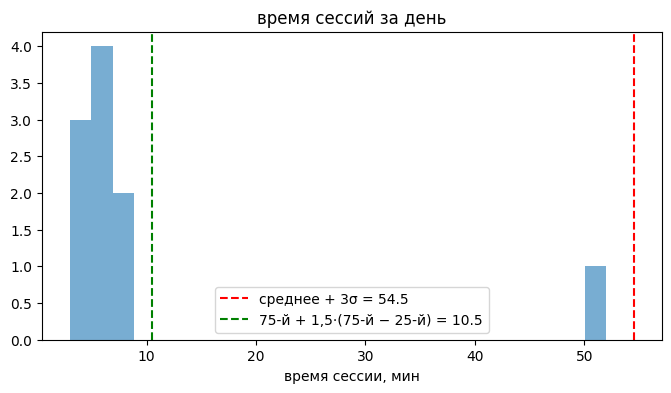

In [8]:
plt.hist(t, bins=25, alpha=0.6)
plt.axvline(up_3s, color='r', ls='--', label=f'среднее + 3σ = {up_3s:.1f}')
plt.axvline(up_pct, color='g', ls='--', label=f'75-й + 1,5·(75-й − 25-й) = {up_pct}')
plt.xlabel('время сессии, мин')
plt.title('время сессий за день')
plt.legend()
plt.show()

Правило трёх сигм выбросов не нашло: граница сверху получилась 54,5 мин, а 52 лежит ниже неё. Нижняя граница вообще −34,5 мин, отрицательного времени не бывает, так что уже по этому видно, что правило к этим данным плохо подходит.

Правило перцентилей сразу отметило 52 как выброс, верхняя граница там 10,5 мин, и все остальные значения (3–8 мин) в неё спокойно попадают.

Лучше сработали перцентили. Проблема трёх сигм в том, что значение 52 само участвует в расчёте среднего и σ. Без него среднее было бы 5,3 мин, а σ около 1,6, и граница среднее + 3σ была бы около 10 мин, т.е. 52 оказалось бы далеко за ней. Но с ним среднее выросло до 10 (хотя медиана 5,5), а σ до 14,8, и граница отъехала дальше самого выброса. Перцентили же зависят только от того, как значения упорядочены, поэтому одно очень большое значение их почти не сдвигает. К тому же данных всего 10 и они явно не нормальные, а правило трёх сигм опирается как раз на нормальное распределение.

Само значение 52 мин я бы не удаляла сразу, а сначала проверила: возможно, это ошибка логирования или незакрытая вкладка, а возможно, реальная долгая сессия. Если это ошибка, её можно убрать, а если нет, то для описания типичной сессии лучше использовать медиану, а не среднее.